In [1]:
# Cell 1 - install deps
!pip install --upgrade google-genai gradio requests pillow

  Using cached pillow-13.0.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)


AQ.Ab8RN6JhMYnpyvdVfOgbOADLvf1FUgQDcSWykQKjmg1eacukPA

In [2]:
from getpass import getpass
import os

print("Paste keys when prompted:")

GEMINI_KEY = getpass("Gemini API key: ")
os.environ["GEMINI_API_KEY"] = GEMINI_KEY

Paste keys when prompted:
Gemini API key: ··········


sk_aOyBZzWXMpnwHSqDfWqqN472B0O81IUv

In [3]:
import os
from getpass import getpass

os.environ["POLLINATIONS_API_KEY"] = getpass(
    "Enter your Pollinations API key: "
)

Enter your Pollinations API key: ··········


In [4]:
import os
import requests
from PIL import Image
from io import BytesIO
from urllib.parse import quote


def call_hf_image(prompt):
    """
    Generate an image through Pollinations.
    Keeps the original function name and return format
    so it can replace the old function in your agent.
    """
    try:
        # This must be a Pollinations API key, NOT an HF token.
        api_key = os.environ.get("POLLINATIONS_API_KEY")

        if not api_key:
            return {
                "error": (
                    "Pollinations API key is missing. "
                    "Set POLLINATIONS_API_KEY first."
                )
            }

        model_id = "black-forest-labs/flux.1-schnell"
        encoded_prompt = quote(prompt, safe="")
        api_url = f"https://gen.pollinations.ai/image/{encoded_prompt}"

        headers = {"Authorization": f"Bearer {api_key}"}
        params = {
            "model": model_id,
            "width": 768,
            "height": 768,
        }

        print(f"Generating image using Pollinations model '{model_id}'")
        print(f"Prompt: {prompt}")

        response = requests.get(
            api_url,
            headers=headers,
            params=params,
            timeout=180
        )

        if response.status_code != 200:
            return {
                "error": (
                    f"Pollinations API returned "
                    f"{response.status_code}: {response.text[:1000]}"
                )
            }

        content_type = response.headers.get("Content-Type", "")

        if not content_type.startswith("image/"):
            return {
                "error": (
                    "API did not return an image. "
                    f"Content-Type: {content_type}; "
                    f"Response: {response.text[:500]}"
                )
            }

        img = Image.open(BytesIO(response.content)).convert("RGB")
        return {"pil_image": img}

    except Exception as e:
        return {
            "error": (
                f"Failed to generate image via Pollinations: "
                f"{type(e).__name__}: {str(e)}"
            )
        }

In [5]:
# Cell 3 - imports and Gemini client
import google.genai as genai
import requests, json, time, base64, os
from PIL import Image
from io import BytesIO
from IPython.display import HTML, display

import sys
import matplotlib.pyplot as plt

# Initialize Gemini client only if key provided
if os.environ.get('GEMINI_API_KEY'):
    client = genai.Client(api_key=os.environ['GEMINI_API_KEY'])
    GEMINI_AVAILABLE = True
    print("Gemini key found and client initialized.")
else:
    GEMINI_AVAILABLE = False
    client = None
    print("Gemini key not found — text generation disabled until you set GEMINI_KEY.")


Gemini key found and client initialized.


In [6]:
# Cell 5 - function: generate text with Gemini
def call_gemini(prompt):
    try:
        if not GEMINI_AVAILABLE or client is None:
            return {"type": "text", "content": "Gemini client is not initialized."}

        # Use the updated client SDK format with the recommended model ID
        response = client.models.generate_content(
            model='gemini-3.5-flash',
            contents=prompt,
        )
        return {"type": "text", "content": response.text}
    except Exception as e:
        return {"type": "text", "content": f"Gemini error: {e}"}

In [7]:
# Cell 4 - simple intent classification
def classify_intent(user_text):
    t = user_text.lower()
    # image triggers
    if "image" in t or "picture" in t or "photo" in t or t.startswith("create me an image"):
        return "image"
    # text/generation/tranform triggers
    if any(k in t for k in ["write", "summarize", "explain", "draft", "describe", "generate text", "summarise"]):
        return "text"
    # fallback: if contains short multimedia instructions mention both -> prefer image
    if "create me" in t and "and" in t and ("video" in t or "image" in t):
        if "image" in t: return "image"
    # Default -> text
    return "text"

In [8]:
def handle_user_request(user_text):
    intent = classify_intent(user_text)
    print(f"[Agent] detected intent: {intent}")

    if intent == "text":
        return {"type": "text", "content": call_gemini(user_text)['content']}
    elif intent == "image":
        return {"type": "image", "content": call_hf_image(user_text)}
    else:
        return {"type": "text", "content": "Sorry, I don't understand."}

In [9]:
from PIL import Image
from IPython.display import display, HTML
import base64, io, requests, numpy as np

def display_image_response(image_input, filename="/content/generated_image.png"):
    # Extract PIL Image
    if isinstance(image_input, dict):
        if 'pil_image' in image_input:
            img = image_input['pil_image']
        elif 'b64_json' in image_input:
            image_bytes = base64.b64decode(image_input['b64_json'])
            img = Image.open(io.BytesIO(image_bytes))
        elif 'url' in image_input:
            image_bytes = requests.get(image_input['url']).content
            img = Image.open(io.BytesIO(image_bytes))
        else:
            raise TypeError(f"Unsupported dict keys: {image_input.keys()}")
    elif isinstance(image_input, Image.Image):
        img = image_input
    elif isinstance(image_input, str):
        img = Image.open(image_input)
    elif isinstance(image_input, bytes):
        img = Image.open(io.BytesIO(image_input))
    elif isinstance(image_input, np.ndarray):
        img = Image.fromarray(image_input)
    else:
        raise TypeError(f"Unsupported image type: {type(image_input)}")

    # Save image
    img.save(filename)

    # Display thumbnail
    display(img.resize((256, 256)))
    time.sleep(2)

In [10]:
import textwrap

def pretty_print(text, width=80):
    print("\n".join(textwrap.wrap(text, width)))

Multimodal Agent (demo). Type 'exit' to quit.
You: image of car
[Agent] detected intent: image
Generating image using Pollinations model 'black-forest-labs/flux.1-schnell'
Prompt: image of car

Agent (image):


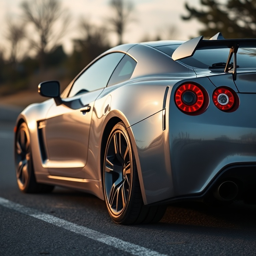


---

You: image of bmw
[Agent] detected intent: image
Generating image using Pollinations model 'black-forest-labs/flux.1-schnell'
Prompt: image of bmw

Agent (image):


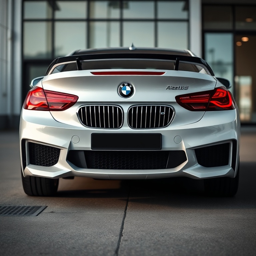


---

You: image of kawasaki
[Agent] detected intent: image
Generating image using Pollinations model 'black-forest-labs/flux.1-schnell'
Prompt: image of kawasaki

Agent (image):


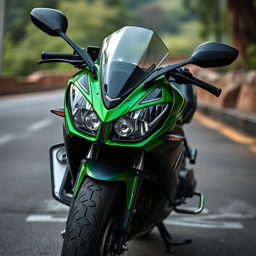


---

You: image of alone girl
[Agent] detected intent: image
Generating image using Pollinations model 'black-forest-labs/flux.1-schnell'
Prompt: image of alone girl

Agent (image):


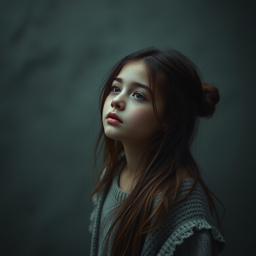


---

You: image of me
[Agent] detected intent: image
Generating image using Pollinations model 'black-forest-labs/flux.1-schnell'
Prompt: image of me

Agent (image):


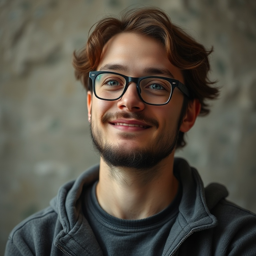


---

You: image of buddha
[Agent] detected intent: image
Generating image using Pollinations model 'black-forest-labs/flux.1-schnell'
Prompt: image of buddha

Agent (image):


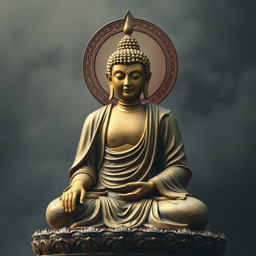


---

You: image of shiva
[Agent] detected intent: image
Generating image using Pollinations model 'black-forest-labs/flux.1-schnell'
Prompt: image of shiva

Agent (image):


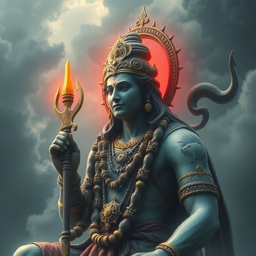


---

You: image of black forest
[Agent] detected intent: image
Generating image using Pollinations model 'black-forest-labs/flux.1-schnell'
Prompt: image of black forest

Agent (image):


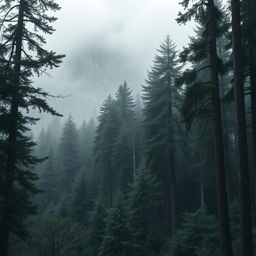


---

You: image of black pink rose
[Agent] detected intent: image
Generating image using Pollinations model 'black-forest-labs/flux.1-schnell'
Prompt: image of black pink rose

Agent (image):


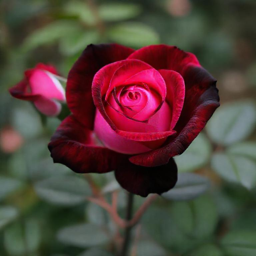


---

You: image of water bottle
[Agent] detected intent: image
Generating image using Pollinations model 'black-forest-labs/flux.1-schnell'
Prompt: image of water bottle

Agent (image):


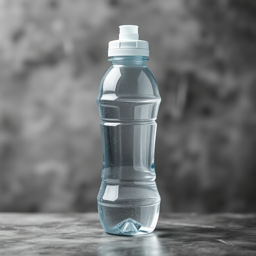


---

You: exit


In [13]:
print("Multimodal Agent (demo). Type 'exit' to quit.")

image_counter = 1  # optional: number images uniquely

while True:
    q = input("You: ")
    if q.strip().lower() in ("exit","quit"):
        break

    out = handle_user_request(q)

    if out['type'] == 'text':
        print("\n", pretty_print(out['content']))
    elif out['type'] == 'image':
        content = out['content']
        if isinstance(content, dict) and 'error' in content:
            print(f"\nAgent (image error): {content['error']}")
        else:
            print("\nAgent (image):")
            # Save with unique filename each time
            filename = f"generated_image_{image_counter}.png"
            display_image_response(content, filename)
            image_counter += 1
    else:
        print("Unknown output type:", out.get('type'))

    print("\n---\n")